# Feature B — Review Sentiment Analysis (All in One)

This single Colab notebook covers preprocessing, EDA, complete resumable Gemini labelling, manual validation, model development and comparison, fine-tuning, final selection, product/category summaries, exports, and final verification.

Existing Gemini labels are reused by model name, prompt version, review ID, and review-body hash. Changing the API key does not invalidate the checkpoint.

In [1]:
!pip install -q google-genai python-dotenv pyarrow tqdm scikit-learn matplotlib seaborn joblib


In [2]:
import os
import sys
from pathlib import Path
from getpass import getpass

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    cohen_kappa_score,
)

from google.colab import drive

drive.mount("/content/drive")

PROJECT = Path(
    "/content/drive/MyDrive/Amazon Mini Projects/"
    "Amazon-Marketplace-Product-Intelligence"
)

assert PROJECT.exists(), f"Wrong project path: {PROJECT}"

if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

from analysis.cleaning import load_clean
from analysis.labelling_model2 import GeminiLabeller
from analysis.sentiment_checkpointed import (
    prepare_reviews,
    label_with_checkpoint,
)

CHECKPOINT_DIR = PROJECT / "data" / "checkpoints" / "ReviewSentiment"
OUTPUT_DIR = PROJECT / "data" / "models" / "ReviewSentiment"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL = "gemini-3.5-flash-lite"
PROMPT_VERSION = "sentiment_v2"
BATCH_SIZE = 10
REQUEST_DELAY = 6.5

try:
    from google.colab import userdata
    saved_key = userdata.get("GEMINI_API_KEY")
except Exception:
    saved_key = None

if saved_key:
    os.environ["GEMINI_API_KEY"] = saved_key
elif not os.getenv("GEMINI_API_KEY"):
    os.environ["GEMINI_API_KEY"] = getpass("Gemini API key: ")

print("Model:", MODEL)
print("Prompt version:", PROMPT_VERSION)
print("Existing checkpoint labels will be reused before API requests.")

Mounted at /content/drive
Gemini API key: ··········
Model: gemini-3.5-flash-lite
Prompt version: sentiment_v2
Existing checkpoint labels will be reused before API requests.


## 1. Preprocessing, EDA, and interpretation

Rating-derived silver labels are 1-2 negative, 3 neutral, and 4-5 positive.
Ratings are imperfect labels because review text can disagree with ratings.
All languages remain in scope.


Loaded 859 products, 9251 reviews from cache
Products: 859 Reviews: 9251 Duplicate IDs: 0
English share: 85.6%


,reviewer_name,rating,title,body,date,country,verified_purchase,helpful_votes,asin,search_keyword,brand,body_clean,title_clean,language,star_sentiment,review_id,body_hash,language_group
0,diamela,5.0,Great earbuds for the price,I’m really happy with these earbuds. The sound...,"August 18, 2026",United States,True,1.0,B0H9LHWBDK,wireless earbuds,XIAOWTEK,I’m really happy with these earbuds. The sound...,Great earbuds for the price,en,positive,400edd3929e152363ca3,28c56391fc148aeb22c7906b2d7d08f182e9c7ad847ac1...,en
1,Shakira Peñas,5.0,Recommended,These wireless earbuds have excellent sound qu...,"August 23, 2026",United States,True,1.0,B0H9LHWBDK,wireless earbuds,XIAOWTEK,These wireless earbuds have excellent sound qu...,Recommended,en,positive,6abfc5e0382ded81dfab,4f79f8ad61ebf37780d50f159602b2e908d0ade874248e...,en
2,Yuriko Matsumoto,5.0,Audífonos,I’m really impressed with these wireless earbu...,"August 24, 2026",United States,True,NaN,B0H9LHWBDK,wireless earbuds,XIAOWTEK,I’m really impressed with these wireless earbu...,Audífonos,en,positive,8a8047dbb1887280b1c7,c09b6fc638cf0592b3279f96a0b4eec49a7bde8746ccc9...,en
3,Yadier Díaz,5.0,Comfortably,I’m really happy with these wireless earbuds. ...,"August 18, 2026",United States,True,4.0,B0H9LHWBDK,wireless earbuds,XIAOWTEK,I’m really happy with these wireless earbuds. ...,Comfortably,en,positive,27482cea7efacdd22cfd,885d7de92126a3a8937df62431caec5ab65fac1f8711a1...,en
4,Dayitha,5.0,Great Value Wireless Earbuds,I’m pleasantly surprised by these earbuds. The...,"July 11, 2026",United States,True,4.0,B0H9LHWBDK,wireless earbuds,XIAOWTEK,I’m pleasantly surprised by these earbuds. The...,Great Value Wireless Earbuds,en,positive,6b44139b99f34a52381a,b24f78e0ffa1db40b5cae7e5cdeb99034da218264fc1f0...,en
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9246,sanjeev.rathore,1.0,Not sustainable,I've been using this guitar for the last four ...,"July 20, 2024",Saudi Arabia,True,NaN,B0002GXZK4,yamaha accoustic guitar,Jasmine,I've been using this guitar for the last four ...,Not sustainable,en,negative,eef372c2cf372c6f3cef,74b9c1f4d139d3ad8bbe83a38908bf93a48baa8915c6b2...,en
9247,Amazon Customer,5.0,A Very Nice Guitar,"After some research online, we decided on this...","September 3, 2021",Canada,True,NaN,B0002GXZK4,yamaha accoustic guitar,Jasmine,"After some research online, we decided on this...",A Very Nice Guitar,en,positive,60dee4e34ca9fadf1d7f,2bfabe27bc6c0cdddcda59eb8ac71cb21cd3b02b9695cf...,en
9248,Kaan,2.0,Tel kalitesi,Gitar üzerindeki teller akort tutmaz bir durum...,"November 18, 2024",Turkey,True,NaN,B0002GXZK4,yamaha accoustic guitar,Jasmine,Gitar üzerindeki teller akort tutmaz bir durum...,Tel kalitesi,tr,negative,572b3bcc23ad291fe421,0e0730dc45f13ac0b968021707fefef2cd47b2b5b2bc51...,non_en
9249,amadine,5.0,AMAZING Guitar!,I got this guitar for my son as his birthday p...,"April 18, 2013",United Kingdom,True,NaN,B0002GXZK4,yamaha accoustic guitar,Jasmine,I got this guitar for my son as his birthday p...,AMAZING Guitar!,en,positive,31c704bdf4436bea62af,a79f47897f9fb068e89072709e028493386380a4d96bfe...,en


,missing_percent
helpful_votes,52.610529
brand,3.696898
rating,0.000000
reviewer_name,0.000000
date,0.000000
title,0.000000
country,0.000000
verified_purchase,0.000000
asin,0.000000
body,0.000000


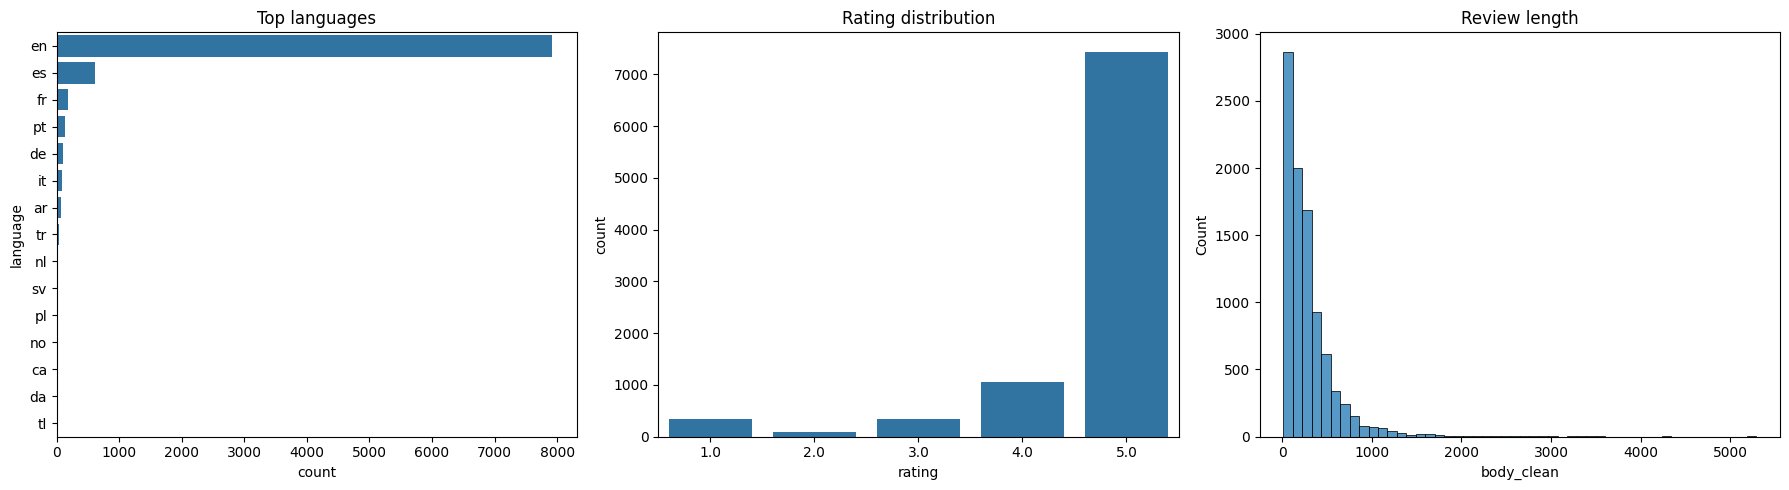

EDA decision: native multilingual Gemini; language-specific checks; log every failure; no translation unless later automatic evidence shows a problem.


In [3]:
products,reviews=load_clean(); df=prepare_reviews(reviews)
print('Products:',len(products),'Reviews:',len(df),'Duplicate IDs:',df.review_id.duplicated().sum())
print('English share:',f"{df.language.eq('en').mean():.1%}"); display(df); display(df.isna().mean().mul(100).sort_values(ascending=False).to_frame('missing_percent'))
fig,axes=plt.subplots(1,3,figsize=(18,5))
sns.countplot(data=df,y='language',order=df.language.value_counts().head(15).index,ax=axes[0]); axes[0].set_title('Top languages')
sns.countplot(data=df,x='rating',ax=axes[1]); axes[1].set_title('Rating distribution')
sns.histplot(df.body_clean.str.len(),bins=50,ax=axes[2]); axes[2].set_title('Review length')
plt.tight_layout(); plt.savefig(OUTPUT_DIR/'sentiment_eda.png',dpi=160,bbox_inches='tight'); plt.show()
print('EDA decision: native multilingual Gemini; language-specific checks; log every failure; no translation unless later automatic evidence shows a problem.')

## 2. Recover and complete the Gemini labelling

The existing checkpoint is recovered first. Only reviews without a valid saved label are sent to Gemini. The checkpoint is saved after every batch of ten reviews. If quota stops the run, rerun this notebook later; completed reviews will not be requested again.

In [4]:
# =========================================================
# RECOVER PREVIOUS GEMINI RUN WITHOUT AN API CALL
# =========================================================

VALID_SENTIMENTS = [
    "positive",
    "neutral",
    "negative",
]

pilot_parts = []

for _, group in df[
    df["star_sentiment"].notna()
].groupby(
    ["language_group", "star_sentiment"],
    observed=True,
):
    pilot_parts.append(
        group.sample(
            n=min(20, len(group)),
            random_state=42,
        )
    )

pilot = (
    pd.concat(pilot_parts)
    .drop_duplicates("review_id")
    .reset_index(drop=True)
)

safe_model_name = MODEL.replace("/", "_")

checkpoint = (
    CHECKPOINT_DIR
    / f"labels__{safe_model_name}__{PROMPT_VERSION}.parquet"
)

recovery_frames = []

if checkpoint.exists():
    checkpoint_labels = pd.read_parquet(checkpoint)

    # Refuse to replace a broader checkpoint with a narrower dataset.
    previous_review_ids = set(
        checkpoint_labels["review_id"].astype(str)
    )
    current_review_ids = set(
        df["review_id"].astype(str)
    )
    missing_previous_ids = (
        previous_review_ids - current_review_ids
    )

    print(
        "Reviews represented by existing checkpoint:",
        len(previous_review_ids),
    )
    print(
        "Previous review IDs absent from current data:",
        len(missing_previous_ids),
    )

    if missing_previous_ids:
        raise RuntimeError(
            "The current cleaned dataset is missing reviews "
            "that exist in the checkpoint. Stop here so old "
            "data is not dropped. Restore/use the cumulative "
            "reviews_clean.parquet dataset."
        )

    if "model_name" in checkpoint_labels.columns:
        checkpoint_labels = checkpoint_labels[
            checkpoint_labels["model_name"].eq(MODEL)
        ]

    if "prompt_version" in checkpoint_labels.columns:
        checkpoint_labels = checkpoint_labels[
            checkpoint_labels["prompt_version"].eq(
                PROMPT_VERSION
            )
        ]

    checkpoint_labels = checkpoint_labels[
        checkpoint_labels["sentiment"].isin(
            VALID_SENTIMENTS
        )
    ][
        ["review_id", "body_hash", "sentiment"]
    ].copy()

    checkpoint_labels["priority"] = 2
    recovery_frames.append(checkpoint_labels)

    print(
        "Valid labels in checkpoint:",
        len(checkpoint_labels),
    )

final_export = (
    OUTPUT_DIR / "reviews_with_sentiment.csv"
)

if final_export.exists():
    exported = pd.read_csv(final_export)

    required = {
        "review_id",
        "body_hash",
        "gemini_sentiment",
    }

    if required.issubset(exported.columns):
        exported = exported[
            exported["gemini_sentiment"].isin(
                VALID_SENTIMENTS
            )
        ][
            [
                "review_id",
                "body_hash",
                "gemini_sentiment",
            ]
        ].copy()

        exported = exported.rename(
            columns={
                "gemini_sentiment": "sentiment"
            }
        )

        exported["priority"] = 1
        recovery_frames.append(exported)

        print(
            "Valid labels in saved Gemini column:",
            len(exported),
        )

if not recovery_frames:
    raise RuntimeError(
        "No reusable Gemini labels were found."
    )

recovered = (
    pd.concat(
        recovery_frames,
        ignore_index=True,
    )
    .sort_values("priority")
    .drop_duplicates(
        ["review_id", "body_hash"],
        keep="last",
    )
)

labelled_all = (
    df.drop(
        columns=["sentiment"],
        errors="ignore",
    )
    .merge(
        recovered[
            [
                "review_id",
                "body_hash",
                "sentiment",
            ]
        ],
        on=["review_id", "body_hash"],
        how="left",
        validate="one_to_one",
    )
)

checkpoint_output = labelled_all[
    ["review_id", "body_hash", "sentiment"]
].copy()

checkpoint_output["model_name"] = MODEL
checkpoint_output["prompt_version"] = PROMPT_VERSION

temporary_checkpoint = checkpoint.with_suffix(
    ".tmp.parquet"
)

checkpoint_output.to_parquet(
    temporary_checkpoint,
    index=False,
)

temporary_checkpoint.replace(checkpoint)

pilot_labelled = (
    pilot.drop(
        columns=["sentiment"],
        errors="ignore",
    )
    .merge(
        labelled_all[
            [
                "review_id",
                "body_hash",
                "sentiment",
            ]
        ],
        on=["review_id", "body_hash"],
        how="left",
        validate="one_to_one",
    )
)

full_completed = int(
    labelled_all["sentiment"]
    .isin(VALID_SENTIMENTS)
    .sum()
)

pilot_completed = int(
    pilot_labelled["sentiment"]
    .isin(VALID_SENTIMENTS)
    .sum()
)

print("Pilot size:", len(pilot))
print(
    "Gemini labels recovered:",
    full_completed,
    "/",
    len(labelled_all),
)
print(
    "Pilot labels recovered:",
    pilot_completed,
    "/",
    len(pilot_labelled),
)
print("Checkpoint:", checkpoint)

print("Checkpoint recovery successful.")

# =========================================================
# LABEL ONLY THE UNFINISHED REVIEWS
# =========================================================

if full_completed < len(labelled_all):
    print(
        "Starting resumable API labelling for",
        len(labelled_all) - full_completed,
        "unfinished reviews.",
    )

    full_labeller = GeminiLabeller(
        model_name=MODEL,
        batch_size=BATCH_SIZE,
        request_delay=REQUEST_DELAY,
    )

    labelled_all, checkpoint = label_with_checkpoint(
        reviews=df,
        labeller=full_labeller,
        checkpoint_dir=CHECKPOINT_DIR,
        prompt_version=PROMPT_VERSION,
        batch_size=BATCH_SIZE,
    )
else:
    print("All Gemini labels were already present; no API call was made.")

full_completed = int(
    labelled_all["sentiment"].isin(VALID_SENTIMENTS).sum()
)
remaining = len(labelled_all) - full_completed

# Always save a review-level partial export for inspection.
partial_export = OUTPUT_DIR / "reviews_with_gemini_sentiment_partial.csv"
labelled_all.to_csv(
    partial_export,
    index=False,
    encoding="utf-8-sig",
)

print("Completed Gemini labels:", full_completed, "/", len(labelled_all))
print("Remaining Gemini labels:", remaining)
print("Checkpoint:", checkpoint)
print("Partial export:", partial_export)

if remaining > 0:
    raise RuntimeError(
        "Gemini labelling is incomplete, normally because quota "
        "stopped the run. Wait for quota availability and rerun "
        "this notebook. The checkpoint will reuse completed labels."
    )

# Rebuild the pilot from the now-complete labels.
pilot_labelled = (
    pilot.drop(columns=["sentiment"], errors="ignore")
    .merge(
        labelled_all[["review_id", "body_hash", "sentiment"]],
        on=["review_id", "body_hash"],
        how="left",
        validate="one_to_one",
    )
)

pilot_completed = int(
    pilot_labelled["sentiment"].isin(VALID_SENTIMENTS).sum()
)

if pilot_completed != len(pilot_labelled):
    raise RuntimeError("The completed Gemini pilot is unexpectedly incomplete.")

complete_csv = OUTPUT_DIR / "reviews_with_gemini_sentiment_complete.csv"
complete_parquet = OUTPUT_DIR / "reviews_with_gemini_sentiment_complete.parquet"
labelled_all.to_csv(complete_csv, index=False, encoding="utf-8-sig")
labelled_all.to_parquet(complete_parquet, index=False)

print("All Gemini review labels are complete.")
print("Complete Gemini CSV:", complete_csv)
print("Complete Gemini Parquet:", complete_parquet)


Reviews represented by existing checkpoint: 9251
Previous review IDs absent from current data: 0
Valid labels in checkpoint: 9251
Valid labels in saved Gemini column: 9251
Pilot size: 120
Gemini labels recovered: 9251 / 9251
Pilot labels recovered: 120 / 120
Checkpoint: /content/drive/MyDrive/Amazon Mini Projects/Amazon-Marketplace-Product-Intelligence/data/checkpoints/ReviewSentiment/labels__gemini-3.5-flash-lite__sentiment_v2.parquet
Checkpoint recovery successful.
All Gemini labels were already present; no API call was made.
Completed Gemini labels: 9251 / 9251
Remaining Gemini labels: 0
Checkpoint: /content/drive/MyDrive/Amazon Mini Projects/Amazon-Marketplace-Product-Intelligence/data/checkpoints/ReviewSentiment/labels__gemini-3.5-flash-lite__sentiment_v2.parquet
Partial export: /content/drive/MyDrive/Amazon Mini Projects/Amazon-Marketplace-Product-Intelligence/data/models/ReviewSentiment/reviews_with_gemini_sentiment_partial.csv
All Gemini review labels are complete.
Complete Gem

## 3. Pilot silver-label validation

The 120 pilot predictions are loaded from the checkpoint. Agreement with
ratings is reported as silver-label agreement, not human accuracy.


,value
pilot_reviews,120.000000
silver_agreement,0.691667
silver_macro_f1,0.666316
cohen_kappa,0.537500


              precision    recall  f1-score   support

    positive       0.90      0.88      0.89        40
     neutral       0.60      0.30      0.40        40
    negative       0.59      0.90      0.71        40

    accuracy                           0.69       120
   macro avg       0.70      0.69      0.67       120
weighted avg       0.70      0.69      0.67       120



,language_group,reviews,silver_agreement,silver_macro_f1
0,en,60,0.683333,0.647625
1,non_en,60,0.700000,0.684077


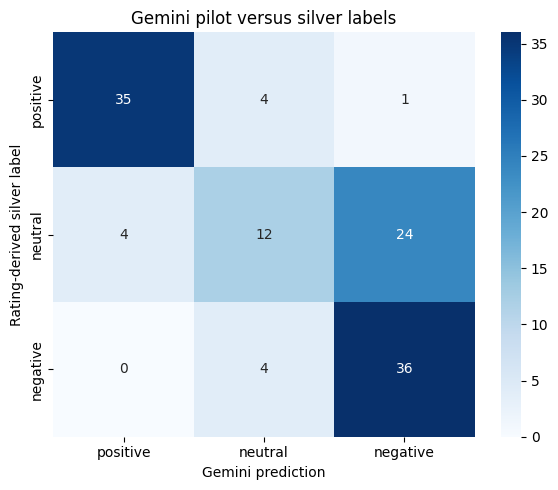

In [5]:
# =========================================================
# PILOT VALIDATION WITHOUT GEMINI API
# =========================================================

valid = pilot_labelled[
    pilot_labelled["sentiment"].isin(
        VALID_SENTIMENTS
    )
    & pilot_labelled["star_sentiment"].isin(
        VALID_SENTIMENTS
    )
].copy()

silver_metrics = pd.Series({
    "pilot_reviews": len(valid),
    "silver_agreement": accuracy_score(
        valid["star_sentiment"],
        valid["sentiment"],
    ),
    "silver_macro_f1": f1_score(
        valid["star_sentiment"],
        valid["sentiment"],
        labels=VALID_SENTIMENTS,
        average="macro",
        zero_division=0,
    ),
    "cohen_kappa": cohen_kappa_score(
        valid["star_sentiment"],
        valid["sentiment"],
    ),
})

display(silver_metrics.to_frame("value"))

print(
    classification_report(
        valid["star_sentiment"],
        valid["sentiment"],
        labels=VALID_SENTIMENTS,
        zero_division=0,
    )
)

language_rows = []

for language_group, group in valid.groupby(
    "language_group"
):
    language_rows.append({
        "language_group": language_group,
        "reviews": len(group),
        "silver_agreement": accuracy_score(
            group["star_sentiment"],
            group["sentiment"],
        ),
        "silver_macro_f1": f1_score(
            group["star_sentiment"],
            group["sentiment"],
            labels=VALID_SENTIMENTS,
            average="macro",
            zero_division=0,
        ),
    })

display(pd.DataFrame(language_rows))

pilot_cm = confusion_matrix(
    valid["star_sentiment"],
    valid["sentiment"],
    labels=VALID_SENTIMENTS,
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    pilot_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=VALID_SENTIMENTS,
    yticklabels=VALID_SENTIMENTS,
)

plt.xlabel("Gemini prediction")
plt.ylabel("Rating-derived silver label")
plt.title("Gemini pilot versus silver labels")
plt.tight_layout()
plt.show()


## 4. Manual validation, model comparison, fine-tuning, and selection

The persistent manual-label CSV is loaded from the checkpoint directory.
The pilot is excluded from local-model training to prevent leakage. Candidate
models are compared using both silver and human labels; complete coverage is
required for final selection.


Completed manual labels: 60
Unchecked rows excluded: 0


manual_sentiment,negative,neutral,positive,All
language_group,,,,
en,16,0,14,30
non_en,16,3,11,30
All,32,3,25,60


Manual labels accepted.
Silver training reviews: 9109
Independent pilot reviews: 120
Word TF-IDF model trained.
Character TF-IDF model trained.
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best parameters:
{'classifier__C': 3.0, 'tfidf__ngram_range': (3, 6)}
Best cross-validation macro-F1: 0.5894


,model,silver_agreement,silver_macro_f1,manual_accuracy,manual_macro_f1,manual_kappa,minimum_language_macro_f1,coverage,selection_score,eligible_for_final
0,Gemini: gemini-3.5-flash-lite,0.691667,0.666316,0.850000,0.718250,0.742243,0.596581,1.0,0.696006,True
1,Word TF-IDF + Logistic Regression,0.591667,0.546667,0.733333,0.524402,0.528256,0.514778,1.0,0.525378,True
2,Character TF-IDF + Logistic Regression,0.566667,0.530196,0.700000,0.500000,0.471107,0.490969,1.0,0.500220,True
3,Fine-tuned Character TF-IDF + Logistic Regression,0.541667,0.492194,0.650000,0.463703,0.389239,0.442500,1.0,0.459649,True


Selected model: Gemini: gemini-3.5-flash-lite
Gemini coverage: 100.0%
Final coverage: 9251 / 9251
Manual accuracy: 0.85
Manual macro-F1: 0.7182
Cohen's kappa: 0.7422
              precision    recall  f1-score   support

    positive       1.00      0.88      0.94        25
     neutral       0.22      0.67      0.33         3
    negative       0.93      0.84      0.89        32

    accuracy                           0.85        60
   macro avg       0.72      0.80      0.72        60
weighted avg       0.92      0.85      0.88        60



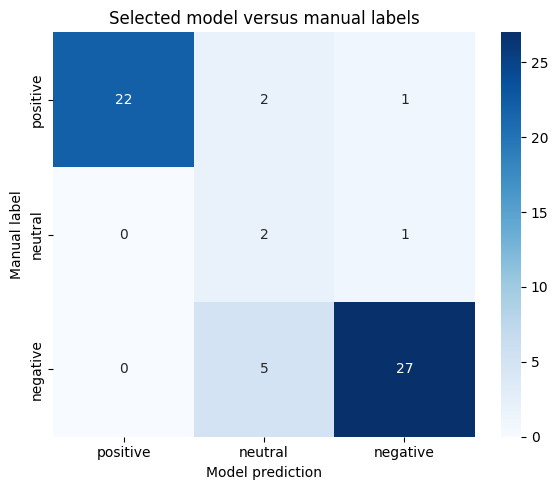

,language_group,reviews,manual_accuracy,manual_macro_f1
0,en,30,0.833333,0.596581
1,non_en,30,0.866667,0.785202


Category summary uses: search_keyword

FEATURE B COMPLETED
Selected model: Gemini: gemini-3.5-flash-lite
Final reviews: 9251
Gemini labels: 9251
Manual labels: 60
Saved to: /content/drive/MyDrive/Amazon Mini Projects/Amazon-Marketplace-Product-Intelligence/data/models/ReviewSentiment


sentiment,asin,positive,neutral,negative,total_reviews,positive_percent,neutral_percent,negative_percent,dominant_sentiment
0,8883707168,10,0,0,10,100.000000,0.000000,0.000000,positive
1,B00004UE2D,10,1,1,12,83.333333,8.333333,8.333333,positive
2,B00006IDM7,8,2,1,11,72.727273,18.181818,9.090909,positive
3,B00006IV0Q,10,0,1,11,90.909091,0.000000,9.090909,positive
4,B00009J580,10,1,2,13,76.923077,7.692308,15.384615,positive
5,B0000ACOV0,13,0,0,13,100.000000,0.000000,0.000000,positive
6,B0000AFSYD,9,1,0,10,90.000000,10.000000,0.000000,positive
7,B0002F58TG,13,0,0,13,100.000000,0.000000,0.000000,positive
8,B0002GXZK4,9,2,2,13,69.230769,15.384615,15.384615,positive
9,B0002IJD76,7,0,0,7,100.000000,0.000000,0.000000,positive


sentiment,search_keyword,positive,neutral,negative,total_reviews,positive_percent,neutral_percent,negative_percent,dominant_sentiment
0,DSLR camera,145,15,10,170,85.294118,8.823529,5.882353,positive
1,USB-C hub,141,29,11,181,77.900552,16.022099,6.077348,positive
2,air purifier,143,33,11,187,76.470588,17.647059,5.882353,positive
3,backpack,170,11,3,184,92.391304,5.978261,1.630435,positive
4,bluetooth speaker,168,12,3,183,91.803279,6.557377,1.639344,positive
5,budget laptop,87,23,33,143,60.839161,16.083916,23.076923,positive
6,candle,404,54,68,526,76.806084,10.266160,12.927757,positive
7,coffee maker,360,63,81,504,71.428571,12.500000,16.071429,positive
8,desk lamp LED,446,43,19,508,87.795276,8.464567,3.740157,positive
9,electric toothbrush,423,74,61,558,75.806452,13.261649,10.931900,positive


,model,silver_agreement,silver_macro_f1,manual_accuracy,manual_macro_f1,manual_kappa,minimum_language_macro_f1,coverage,selection_score,eligible_for_final
0,Gemini: gemini-3.5-flash-lite,0.691667,0.666316,0.850000,0.718250,0.742243,0.596581,1.0,0.696006,True
1,Word TF-IDF + Logistic Regression,0.591667,0.546667,0.733333,0.524402,0.528256,0.514778,1.0,0.525378,True
2,Character TF-IDF + Logistic Regression,0.566667,0.530196,0.700000,0.500000,0.471107,0.490969,1.0,0.500220,True
3,Fine-tuned Character TF-IDF + Logistic Regression,0.541667,0.492194,0.650000,0.463703,0.389239,0.442500,1.0,0.459649,True


,value
total_reviews,9251
gemini_labelled,9251
gemini_coverage,1.0
manual_reviews,60
manual_accuracy,0.85
manual_macro_f1,0.71825
manual_kappa,0.742243
selected_model,Gemini: gemini-3.5-flash-lite


In [6]:
# =========================================================
# CONTINUE AFTER SUCCESSFUL CHECKPOINT RECONSTRUCTION
# Manual validation -> models -> fine-tuning
# -> evaluation -> final predictions -> exports
# =========================================================

import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold
)
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    cohen_kappa_score
)

VALID_SENTIMENTS = [
    "positive",
    "neutral",
    "negative"
]

MIN_MANUAL_LABELS = 45

MANUAL_FILE = (
    CHECKPOINT_DIR /
    "manual_validation_60_v1.csv"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# =========================================================
# 1. LOAD AND VALIDATE MANUAL LABELS
# =========================================================

if not MANUAL_FILE.exists():
    raise FileNotFoundError(
        f"Manual checkpoint not found: {MANUAL_FILE}"
    )

manual_all = pd.read_csv(MANUAL_FILE)

manual_all["manual_sentiment"] = (
    manual_all["manual_sentiment"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

nonempty_manual = manual_all[
    manual_all["manual_sentiment"].ne("")
].copy()

invalid_manual = nonempty_manual[
    ~nonempty_manual["manual_sentiment"]
    .isin(VALID_SENTIMENTS)
]

if not invalid_manual.empty:
    display(invalid_manual)

    raise ValueError(
        "Invalid manual labels found. "
        "Use only positive, neutral or negative."
    )

manual_checked = manual_all[
    manual_all["manual_sentiment"]
    .isin(VALID_SENTIMENTS)
].copy()

print("Completed manual labels:", len(manual_checked))
print(
    "Unchecked rows excluded:",
    len(manual_all) - len(manual_checked)
)

if len(manual_checked) < MIN_MANUAL_LABELS:
    raise RuntimeError(
        f"Only {len(manual_checked)} manual labels "
        f"were found. At least "
        f"{MIN_MANUAL_LABELS} are required."
    )

manual_distribution = pd.crosstab(
    manual_checked["language_group"],
    manual_checked["manual_sentiment"],
    margins=True
)

display(manual_distribution)

print("Manual labels accepted.")

# =========================================================
# 2. PREPARE TRAINING AND EVALUATION DATA
# =========================================================

pilot_evaluation = pilot_labelled[
    pilot_labelled["sentiment"]
    .isin(VALID_SENTIMENTS)
    & pilot_labelled["star_sentiment"]
    .isin(VALID_SENTIMENTS)
].copy()

if len(pilot_evaluation) != 120:
    raise RuntimeError(
        f"Expected 120 complete pilot labels, "
        f"but found {len(pilot_evaluation)}."
    )

# Prevent pilot/manual reviews from entering training.
pilot_hashes = set(
    pilot_evaluation["body_hash"]
)

silver_training = df[
    df["star_sentiment"]
    .isin(VALID_SENTIMENTS)
    & ~df["body_hash"]
    .isin(pilot_hashes)
].copy()

X_train = (
    silver_training["body_clean"]
    .astype(str)
)

y_train = (
    silver_training["star_sentiment"]
    .astype(str)
)

X_pilot = (
    pilot_evaluation["body_clean"]
    .astype(str)
)

y_pilot = (
    pilot_evaluation["star_sentiment"]
    .astype(str)
)

print("Silver training reviews:", len(X_train))
print("Independent pilot reviews:", len(X_pilot))

# =========================================================
# 3. MODEL 1: WORD TF-IDF
# =========================================================

word_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            analyzer="word",
            ngram_range=(1, 2),
            min_df=2,
            max_features=60000,
            sublinear_tf=True,
            strip_accents="unicode"
        )
    ),
    (
        "classifier",
        LogisticRegression(
            C=1.0,
            class_weight="balanced",
            max_iter=1500,
            random_state=42
        )
    )
])

word_model.fit(
    X_train,
    y_train
)

print("Word TF-IDF model trained.")

# =========================================================
# 4. MODEL 2: CHARACTER TF-IDF
# =========================================================

char_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            analyzer="char_wb",
            ngram_range=(3, 5),
            min_df=2,
            max_features=80000,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LogisticRegression(
            C=1.0,
            class_weight="balanced",
            max_iter=1500,
            random_state=42
        )
    )
])

char_model.fit(
    X_train,
    y_train
)

print("Character TF-IDF model trained.")

# =========================================================
# 5. FINE-TUNING
# =========================================================

fine_tuning_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            analyzer="char_wb",
            min_df=2,
            max_features=100000,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        )
    )
])

parameter_grid = {
    "tfidf__ngram_range": [
        (3, 5),
        (3, 6)
    ],
    "classifier__C": [
        0.5,
        1.5,
        3.0
    ]
}

fine_tuning_search = GridSearchCV(
    estimator=fine_tuning_pipeline,
    param_grid=parameter_grid,
    scoring="f1_macro",
    cv=StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    ),
    n_jobs=2,
    verbose=1,
    refit=True,
    return_train_score=True
)

fine_tuning_search.fit(
    X_train,
    y_train
)

tuned_model = (
    fine_tuning_search.best_estimator_
)

print("Best parameters:")
print(fine_tuning_search.best_params_)

print(
    "Best cross-validation macro-F1:",
    round(
        fine_tuning_search.best_score_,
        4
    )
)

fine_tuning_results = pd.DataFrame(
    fine_tuning_search.cv_results_
)

# =========================================================
# 6. JOIN HUMAN AND GEMINI LABELS
# =========================================================

manual_evaluation = manual_checked.merge(
    labelled_all[
        [
            "review_id",
            "sentiment",
            "star_sentiment"
        ]
    ],
    on="review_id",
    how="left",
    validate="one_to_one"
)

missing_manual_gemini = int(
    (
        ~manual_evaluation["sentiment"]
        .isin(VALID_SENTIMENTS)
    ).sum()
)

if missing_manual_gemini > 0:
    raise RuntimeError(
        f"{missing_manual_gemini} manually checked "
        "reviews are missing Gemini predictions."
    )

manual_text = (
    manual_evaluation["body_clean"]
    .astype(str)
)

gemini_name = f"Gemini: {MODEL}"

word_name = (
    "Word TF-IDF + Logistic Regression"
)

char_name = (
    "Character TF-IDF + Logistic Regression"
)

tuned_name = (
    "Fine-tuned Character TF-IDF + "
    "Logistic Regression"
)

# =========================================================
# 7. CREATE MODEL PREDICTIONS
# =========================================================

pilot_predictions = {
    gemini_name:
        pilot_evaluation["sentiment"]
        .astype(str)
        .values,

    word_name:
        word_model.predict(X_pilot),

    char_name:
        char_model.predict(X_pilot),

    tuned_name:
        tuned_model.predict(X_pilot)
}

manual_predictions = {
    gemini_name:
        manual_evaluation["sentiment"]
        .astype(str)
        .values,

    word_name:
        word_model.predict(manual_text),

    char_name:
        char_model.predict(manual_text),

    tuned_name:
        tuned_model.predict(manual_text)
}

manual_evaluation[
    "gemini_prediction"
] = manual_predictions[gemini_name]

manual_evaluation[
    "word_model_prediction"
] = manual_predictions[word_name]

manual_evaluation[
    "char_model_prediction"
] = manual_predictions[char_name]

manual_evaluation[
    "tuned_model_prediction"
] = manual_predictions[tuned_name]


def minimum_language_f1(predictions):

    checked = manual_evaluation[
        [
            "language_group",
            "manual_sentiment"
        ]
    ].copy()

    checked["prediction"] = predictions

    scores = []

    for _, group in checked.groupby(
        "language_group"
    ):
        scores.append(
            f1_score(
                group["manual_sentiment"],
                group["prediction"],
                labels=VALID_SENTIMENTS,
                average="macro",
                zero_division=0
            )
        )

    return min(scores) if scores else 0.0


# =========================================================
# 8. MODEL COMPARISON
# =========================================================

gemini_completed = int(
    labelled_all["sentiment"]
    .isin(VALID_SENTIMENTS)
    .sum()
)

gemini_coverage = (
    gemini_completed /
    len(labelled_all)
)

comparison_rows = []

for model_name in pilot_predictions:

    pilot_prediction = (
        pilot_predictions[model_name]
    )

    manual_prediction = (
        manual_predictions[model_name]
    )

    kappa = cohen_kappa_score(
        manual_evaluation["manual_sentiment"],
        manual_prediction
    )

    if pd.isna(kappa):
        kappa = 0.0

    coverage = (
        gemini_coverage
        if model_name == gemini_name
        else 1.0
    )

    comparison_rows.append({
        "model":
            model_name,

        "silver_agreement":
            accuracy_score(
                y_pilot,
                pilot_prediction
            ),

        "silver_macro_f1":
            f1_score(
                y_pilot,
                pilot_prediction,
                labels=VALID_SENTIMENTS,
                average="macro",
                zero_division=0
            ),

        "manual_accuracy":
            accuracy_score(
                manual_evaluation[
                    "manual_sentiment"
                ],
                manual_prediction
            ),

        "manual_macro_f1":
            f1_score(
                manual_evaluation[
                    "manual_sentiment"
                ],
                manual_prediction,
                labels=VALID_SENTIMENTS,
                average="macro",
                zero_division=0
            ),

        "manual_kappa":
            kappa,

        "minimum_language_macro_f1":
            minimum_language_f1(
                manual_prediction
            ),

        "coverage":
            coverage
    })

comparison = pd.DataFrame(
    comparison_rows
)

comparison["selection_score"] = (
    0.70
    * comparison["manual_macro_f1"]

    + 0.15
    * comparison[
        "minimum_language_macro_f1"
    ]

    + 0.10
    * comparison["silver_macro_f1"]

    + 0.05
    * comparison["manual_kappa"]
)

comparison["eligible_for_final"] = (
    comparison["coverage"] >= 0.999
)

comparison = comparison.sort_values(
    "selection_score",
    ascending=False
).reset_index(drop=True)

display(comparison)

# =========================================================
# 9. SELECT FINAL MODEL
# =========================================================

finalists = comparison[
    comparison["model"].isin([
        gemini_name,
        tuned_name
    ])
    & comparison["eligible_for_final"]
].copy()

if finalists.empty:
    raise RuntimeError(
        "No finalist provides complete coverage."
    )

selected_model_name = (
    finalists.iloc[0]["model"]
)

print("Selected model:", selected_model_name)
print(
    "Gemini coverage:",
    f"{gemini_coverage:.1%}"
)

final_df = labelled_all.copy()

final_df["gemini_sentiment"] = (
    final_df["sentiment"]
)

if selected_model_name == gemini_name:

    final_df["final_sentiment"] = (
        final_df["gemini_sentiment"]
    )

    selected_manual_predictions = (
        manual_predictions[gemini_name]
    )

else:
    final_df["final_sentiment"] = (
        tuned_model.predict(
            final_df["body_clean"]
            .astype(str)
        )
    )

    selected_manual_predictions = (
        manual_predictions[tuned_name]
    )

final_completed = int(
    final_df["final_sentiment"]
    .isin(VALID_SENTIMENTS)
    .sum()
)

print(
    "Final coverage:",
    final_completed,
    "/",
    len(final_df)
)

if final_completed != len(final_df):
    raise RuntimeError(
        "Final prediction coverage is incomplete."
    )

# =========================================================
# 10. MANUAL ACCURACY OF SELECTED MODEL
# =========================================================

manual_evaluation[
    "selected_model_prediction"
] = selected_manual_predictions

selected_manual_accuracy = (
    accuracy_score(
        manual_evaluation[
            "manual_sentiment"
        ],
        selected_manual_predictions
    )
)

selected_manual_macro_f1 = (
    f1_score(
        manual_evaluation[
            "manual_sentiment"
        ],
        selected_manual_predictions,
        labels=VALID_SENTIMENTS,
        average="macro",
        zero_division=0
    )
)

selected_manual_kappa = (
    cohen_kappa_score(
        manual_evaluation[
            "manual_sentiment"
        ],
        selected_manual_predictions
    )
)

print(
    "Manual accuracy:",
    round(selected_manual_accuracy, 4)
)

print(
    "Manual macro-F1:",
    round(selected_manual_macro_f1, 4)
)

print(
    "Cohen's kappa:",
    round(selected_manual_kappa, 4)
)

print(
    classification_report(
        manual_evaluation[
            "manual_sentiment"
        ],
        selected_manual_predictions,
        labels=VALID_SENTIMENTS,
        zero_division=0
    )
)

selected_cm = confusion_matrix(
    manual_evaluation["manual_sentiment"],
    selected_manual_predictions,
    labels=VALID_SENTIMENTS
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    selected_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=VALID_SENTIMENTS,
    yticklabels=VALID_SENTIMENTS
)

plt.xlabel("Model prediction")
plt.ylabel("Manual label")
plt.title("Selected model versus manual labels")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "manual_validation_confusion_matrix.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# Language-specific manual evaluation
manual_language_results = []

for language_group, group in (
    manual_evaluation.groupby(
        "language_group"
    )
):
    manual_language_results.append({
        "language_group":
            language_group,

        "reviews":
            len(group),

        "manual_accuracy":
            accuracy_score(
                group["manual_sentiment"],
                group[
                    "selected_model_prediction"
                ]
            ),

        "manual_macro_f1":
            f1_score(
                group["manual_sentiment"],
                group[
                    "selected_model_prediction"
                ],
                labels=VALID_SENTIMENTS,
                average="macro",
                zero_division=0
            )
    })

manual_language_results = pd.DataFrame(
    manual_language_results
)

display(manual_language_results)

# =========================================================
# 11. PRODUCT AND CATEGORY SUMMARIES
# =========================================================

usable = final_df[
    final_df["final_sentiment"]
    .isin(VALID_SENTIMENTS)
].copy()

usable["sentiment"] = (
    usable["final_sentiment"]
)

if (
    "category" in usable.columns
    and usable["category"].notna().any()
):
    category_column = "category"

elif "search_keyword" in usable.columns:
    category_column = "search_keyword"

else:
    raise ValueError(
        "No category or search_keyword "
        "column was found."
    )

print(
    "Category summary uses:",
    category_column
)


def create_summary(data, group_column):

    counts = pd.crosstab(
        data[group_column],
        data["sentiment"]
    ).reindex(
        columns=VALID_SENTIMENTS,
        fill_value=0
    )

    counts["total_reviews"] = (
        counts.sum(axis=1)
    )

    for sentiment in VALID_SENTIMENTS:
        counts[
            f"{sentiment}_percent"
        ] = (
            100
            * counts[sentiment]
            / counts["total_reviews"]
        )

    counts["dominant_sentiment"] = (
        counts[
            VALID_SENTIMENTS
        ].idxmax(axis=1)
    )

    return counts.reset_index()


product_summary = create_summary(
    usable,
    "asin"
)

category_summary = create_summary(
    usable,
    category_column
)

# =========================================================
# 12. SAVE EVERYTHING
# =========================================================

usable.to_csv(
    OUTPUT_DIR /
    "reviews_with_sentiment.csv",
    index=False,
    encoding="utf-8-sig"
)

usable.to_parquet(
    OUTPUT_DIR /
    "reviews_with_sentiment.parquet",
    index=False
)

product_summary.to_csv(
    OUTPUT_DIR /
    "sentiment_by_product.csv",
    index=False,
    encoding="utf-8-sig"
)

category_summary.to_csv(
    OUTPUT_DIR /
    "sentiment_by_category.csv",
    index=False,
    encoding="utf-8-sig"
)

comparison.to_csv(
    OUTPUT_DIR /
    "sentiment_model_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

manual_evaluation.to_csv(
    OUTPUT_DIR /
    "manual_validation_results.csv",
    index=False,
    encoding="utf-8-sig"
)

manual_language_results.to_csv(
    OUTPUT_DIR /
    "manual_validation_by_language.csv",
    index=False,
    encoding="utf-8-sig"
)

fine_tuning_results.to_csv(
    OUTPUT_DIR /
    "sentiment_fine_tuning_results.csv",
    index=False,
    encoding="utf-8-sig"
)

joblib.dump(
    tuned_model,
    OUTPUT_DIR /
    "fine_tuned_sentiment_model.joblib"
)

with open(
    OUTPUT_DIR /
    "selected_model.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(selected_model_name)

final_metrics = pd.Series({
    "total_reviews":
        len(usable),

    "gemini_labelled":
        gemini_completed,

    "gemini_coverage":
        gemini_coverage,

    "manual_reviews":
        len(manual_evaluation),

    "manual_accuracy":
        selected_manual_accuracy,

    "manual_macro_f1":
        selected_manual_macro_f1,

    "manual_kappa":
        selected_manual_kappa,

    "selected_model":
        selected_model_name
})

final_metrics.to_csv(
    OUTPUT_DIR /
    "final_sentiment_metrics.csv",
    header=["value"],
    encoding="utf-8-sig"
)

print("\n====================================")
print("FEATURE B COMPLETED")
print("====================================")
print("Selected model:", selected_model_name)
print("Final reviews:", len(usable))
print("Gemini labels:", gemini_completed)
print("Manual labels:", len(manual_evaluation))
print("Saved to:", OUTPUT_DIR)

display(product_summary.head(10))
display(category_summary.head(10))
display(comparison)
display(final_metrics.to_frame("value"))

## 5. Final verification

Verifies all required files, 9,250 final review rows, valid sentiment labels,
duplicate IDs, manual evaluation, summaries, and the selected model.


In [7]:
# =========================================================
# FINAL FEATURE B VERIFICATION
# =========================================================

from pathlib import Path
import pandas as pd

expected_files = [
    "reviews_with_sentiment.csv",
    "reviews_with_sentiment.parquet",
    "sentiment_by_product.csv",
    "sentiment_by_category.csv",
    "sentiment_model_comparison.csv",
    "manual_validation_results.csv",
    "manual_validation_by_language.csv",
    "sentiment_fine_tuning_results.csv",
    "fine_tuned_sentiment_model.joblib",
    "selected_model.txt",
    "reviews_with_gemini_sentiment_complete.csv",
    "reviews_with_gemini_sentiment_complete.parquet",
    "final_sentiment_metrics.csv"
]

file_check = pd.DataFrame([
    {
        "file": filename,
        "exists": (
            OUTPUT_DIR / filename
        ).exists(),

        "size_bytes": (
            OUTPUT_DIR / filename
        ).stat().st_size
        if (OUTPUT_DIR / filename).exists()
        else 0
    }
    for filename in expected_files
])

display(file_check)

missing_files = file_check[
    ~file_check["exists"]
]

if not missing_files.empty:
    raise RuntimeError(
        "Some required output files are missing."
    )

# Load final results
final_reviews = pd.read_csv(
    OUTPUT_DIR /
    "reviews_with_sentiment.csv"
)

product_results = pd.read_csv(
    OUTPUT_DIR /
    "sentiment_by_product.csv"
)

category_results = pd.read_csv(
    OUTPUT_DIR /
    "sentiment_by_category.csv"
)

model_results = pd.read_csv(
    OUTPUT_DIR /
    "sentiment_model_comparison.csv"
)

manual_results = pd.read_csv(
    OUTPUT_DIR /
    "manual_validation_results.csv"
)

final_metrics = pd.read_csv(
    OUTPUT_DIR /
    "final_sentiment_metrics.csv",
    index_col=0
)

valid_sentiments = [
    "positive",
    "neutral",
    "negative"
]

verification = pd.Series({
    "final_review_rows":
        len(final_reviews),

    "valid_sentiment_rows":
        int(
            final_reviews["sentiment"]
            .isin(valid_sentiments)
            .sum()
        ),

    "missing_sentiments":
        int(
            final_reviews["sentiment"]
            .isna()
            .sum()
        ),

    "invalid_sentiments":
        int(
            (
                ~final_reviews["sentiment"]
                .isin(valid_sentiments)
            ).sum()
        ),

    "duplicate_review_ids":
        int(
            final_reviews["review_id"]
            .duplicated()
            .sum()
        ),

    "product_summary_rows":
        len(product_results),

    "category_summary_rows":
        len(category_results),

    "manual_evaluation_rows":
        len(manual_results)
})

display(
    verification.to_frame("value")
)

if len(final_reviews) != len(df):
    raise RuntimeError(
        f"Expected {len(df)} final reviews, "
        f"but found {len(final_reviews)}."
    )

if verification["missing_sentiments"] > 0:
    raise RuntimeError(
        "Missing final sentiment labels found."
    )

if verification["invalid_sentiments"] > 0:
    raise RuntimeError(
        "Invalid final sentiment labels found."
    )

if verification["duplicate_review_ids"] > 0:
    raise RuntimeError(
        "Duplicate review IDs found."
    )

if len(manual_results) < 45:
    raise RuntimeError(
        "Insufficient manual evaluation rows."
    )

selected_model = (
    OUTPUT_DIR /
    "selected_model.txt"
).read_text(
    encoding="utf-8"
)

print("\nSelected final model:")
print(selected_model)

print("\nModel comparison:")
display(
    model_results.sort_values(
        "selection_score",
        ascending=False
    )
)

print("\nFinal sentiment distribution:")
display(
    final_reviews["sentiment"]
    .value_counts()
    .to_frame("reviews")
)

print("\nFinal sentiment percentages:")
display(
    final_reviews["sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame("percent")
)

print("\n====================================")
print("FINAL VERIFICATION PASSED")
print("Feature B is complete.")
print("Output directory:", OUTPUT_DIR)
print("====================================")

,file,exists,size_bytes
0,reviews_with_sentiment.csv,True,7971255
1,reviews_with_sentiment.parquet,True,4392280
2,sentiment_by_product.csv,True,54323
3,sentiment_by_category.csv,True,2647
4,sentiment_model_comparison.csv,True,824
5,manual_validation_results.csv,True,16770
6,manual_validation_by_language.csv,True,150
7,sentiment_fine_tuning_results.csv,True,2336
8,fine_tuned_sentiment_model.joblib,True,5902852
9,selected_model.txt,True,29


,value
final_review_rows,9251
valid_sentiment_rows,9251
missing_sentiments,0
invalid_sentiments,0
duplicate_review_ids,0
product_summary_rows,848
category_summary_rows,28
manual_evaluation_rows,60



Selected final model:
Gemini: gemini-3.5-flash-lite

Model comparison:


,model,silver_agreement,silver_macro_f1,manual_accuracy,manual_macro_f1,manual_kappa,minimum_language_macro_f1,coverage,selection_score,eligible_for_final
0,Gemini: gemini-3.5-flash-lite,0.691667,0.666316,0.850000,0.718250,0.742243,0.596581,1.0,0.696006,True
1,Word TF-IDF + Logistic Regression,0.591667,0.546667,0.733333,0.524402,0.528256,0.514778,1.0,0.525378,True
2,Character TF-IDF + Logistic Regression,0.566667,0.530196,0.700000,0.500000,0.471107,0.490969,1.0,0.500220,True
3,Fine-tuned Character TF-IDF + Logistic Regression,0.541667,0.492194,0.650000,0.463703,0.389239,0.442500,1.0,0.459649,True



Final sentiment distribution:


,reviews
sentiment,
positive,7524
neutral,1069
negative,658



Final sentiment percentages:


,percent
sentiment,
positive,81.33
neutral,11.56
negative,7.11



FINAL VERIFICATION PASSED
Feature B is complete.
Output directory: /content/drive/MyDrive/Amazon Mini Projects/Amazon-Marketplace-Product-Intelligence/data/models/ReviewSentiment


## Final interpretation and limitations

The complete review dataset is labelled by Gemini using a durable checkpoint, so unchanged reviews are not requested twice. Word and character TF-IDF Logistic Regression approaches are developed and compared with Gemini. The strongest local candidate is fine-tuned using cross-validated macro-F1, and final selection uses blinded manual accuracy, manual macro-F1, multilingual consistency, silver-label performance, and prediction coverage.

A blinded manually checked sample supplies the required human accuracy estimate. Rating-derived sentiment is used only as silver-labelled development/evaluation data and is not used as a prediction feature. Product and category summaries are created from the selected final sentiment predictions.

Limitations include one human annotator, a relatively small manual sample, rating-text disagreement, possible multilingual ambiguity, class imbalance, and possible weakness on the neutral class.